# Hälsostudie

Utredning av en hälsostudie med 800 deltagare. 
Datasetets kolumner är: Ålder, kön, längd, vikt, systoliskt blodtryck, kolesterol, rökare, sjukdom. Det är informationen som ges av deltagarna för studien.

Syftet:
- Hur ser deltagarnas ålder, vikt, längd, blodtryck och kolesterol ut?
- Hur stor del av deltagarna har sjukdomen, och stämmer det med simuleringen?
- Inom vilket intervall ligger det genomsnittliga systoliska blodtrycket?
- Har rökare högre medelblodtryck än icke-rökare?

Analysen innehåller analys, statistik, simulering, konfidensintervall och hypotesprövning

In [3]:
#hämta in numpy, pandas matplotlib, scipy för hypotesprövning och np.random.seed för simuleringar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
np.random.seed(42)

## Inläsning av data

In [4]:
df = pd.read_csv("data/health_study_dataset.csv")       #hämta in dataset
df.head()       #Visa första 5 raderna

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


## Översikt av datan

In [ ]:
df.info()   #info om dataset

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


In [ ]:
df.describe()       #antal, medel, standardavvikelse, min, max, 25%,50% och 75%

,id,age,height,weight,systolic_bp,cholesterol,disease
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,49.426250,171.849250,73.413000,149.178625,4.929150,0.058750
std,231.0844,14.501118,9.804259,13.685059,12.793360,0.848413,0.235303
min,1.0000,18.000000,144.400000,33.700000,106.800000,2.500000,0.000000
25%,200.7500,39.000000,164.775000,64.800000,140.900000,4.327500,0.000000
50%,400.5000,50.000000,171.350000,73.200000,149.400000,4.970000,0.000000
75%,600.2500,59.000000,178.925000,82.600000,157.600000,5.482500,0.000000
max,800.0000,90.000000,200.400000,114.400000,185.900000,7.880000,1.000000


Lägsta vikten är 33,7 kg, och lägsta åldern är 18. Låter lite omrimligt.

## Datakontroll
Kontrollera datan innan vi börjar med analysen, leta efter saknade värden, dubletter och orimliga värden.

In [9]:
# isna/ markerar saknade värden
print(df.isna().sum())

#dublicated markerar rader som är kopior
print("Antal dubletter:", df.duplicated().sum())

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64
Antal dubletter: 0


In [ ]:
# value_counts() räknar hur många gånger värde förekommer, översikt över data
print(df["sex"].value_counts())
print(df["smoker"].value_counts())
print(df["disease"].value_counts())

sex
F    403
M    397
Name: count, dtype: int64
smoker
No     587
Yes    213
Name: count, dtype: int64
disease
0    753
1     47
Name: count, dtype: int64


Orimlig data förekomm tidigare och behöver utredas

In [11]:
df[df["weight"] < 40]

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
23,24,28,F,170.2,38.1,130.5,3.44,No,0
508,509,50,F,155.9,35.5,134.7,3.59,No,0
535,536,50,F,163.8,33.9,148.0,4.59,No,0
709,710,75,F,149.6,33.7,159.1,5.00,Yes,0


Fyra deltagare väger under 40 kg. Alla är kvinnor och längden är normal. De behålls i analysen. Väldigt få personer i analysen, vilket inte påverkar resultatet väldigt lite. Behöver inte bero på fel i datan.

## Beskrivande analys

Beräkna medelvärde, median, min och max för att beskriva deltagarna.

In [ ]:
kolumner = ["age", "weight", "height", "systolic_bp", "cholesterol"]    # lista olika variabler som vi ska utreda

beskrivande = df[kolumner].agg(["mean", "median", "min", "max"])   #agg beräknar flera mått för varje kolumn

beskrivande.T.round(1)  # .T vänder tabellen så att varje variabel blir en rad., round avrundar

,mean,median,min,max
age,49.4,50.0,18.0,90.0
weight,73.4,73.2,33.7,114.4
height,171.8,171.4,144.4,200.4
systolic_bp,149.2,149.4,106.8,185.9
cholesterol,4.9,5.0,2.5,7.9


Tolkning: Medelvärde och median ligger nära varandra för alla variabler, så fördelningarna är jämnt fördelade. Deltagarna är mellan 18 och 90 år. Medelblodtrycket är cirka 149 mmhg, vilket är högt eftersom över 140 mmHg räknas som förhöjt.

### Fördelning av systoliskt blodtryck
Ett histogram visar hur blodtrycket fördelar sig bland deltagarna.

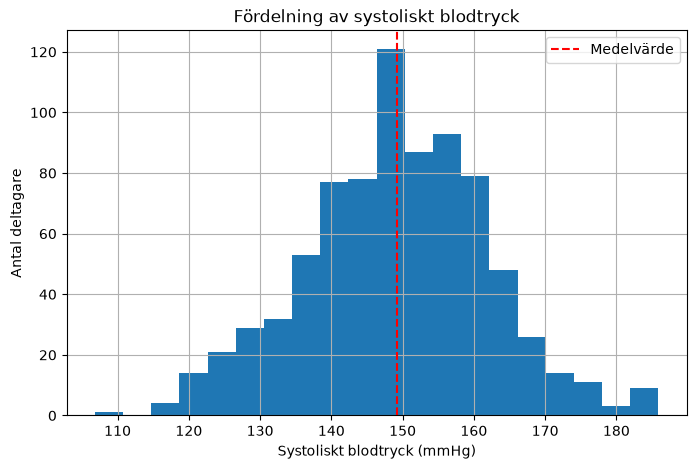

In [ ]:
plt.figure(figsize=(8, 5))      #Skapa figur

plt.hist(df["systolic_bp"], bins=20)    #histogram, 

plt.axvline(df["systolic_bp"].mean(), color="red", linestyle="--", label="Medelvärde") #v6, uppgift 3

plt.title("Fördelning av systoliskt blodtryck") #titel
plt.xlabel("Systoliskt blodtryck (mmHg)") #titel för x
plt.ylabel("Antal deltagare") #titel för y
plt.legend()    #v6, uppgift 4. Gör legenden tydlig med rätt ettiketer
plt.grid(True) #rutnät
plt.show() #visa grafen



Deltagarnas blodtryck är mellan cirka 130 och 170 mmHg. Värdena är fördelade kring medelvärdet, vilket stämmer emd att meddel och median låg nära varandra.

### Vikt per kön
En boxplot jämför viktfördelningen mellan kvinnor och män.

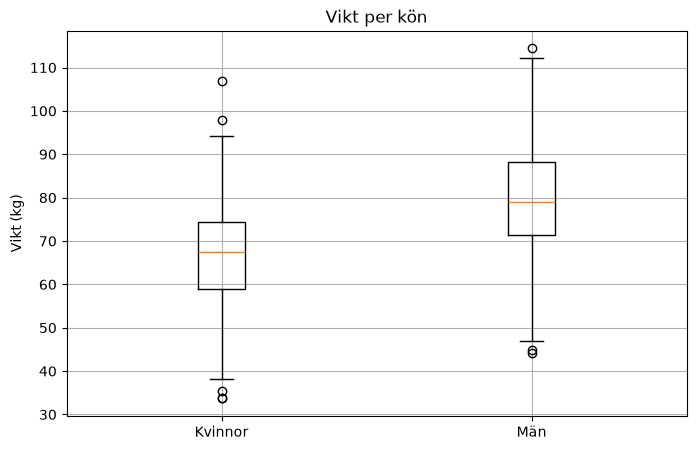

In [ ]:
# Plocka ut vikterna för varje kön
vikt_kvinnor = df[df["sex"] == "F"]["weight"]
vikt_man = df[df["sex"] == "M"]["weight"]

plt.figure(figsize=(8, 5))

plt.boxplot([vikt_kvinnor, vikt_man], tick_labels=["Kvinnor", "Män"])   # boxplot v6, uppgift 3, uppgift 1. Namnen under lådorna

plt.title("Vikt per kön")
plt.ylabel("Vikt (kg)")
plt.grid(True)
plt.show()

Män har en högre medianvikt än kvinnor (cirka 79 kg gentemot 67 kg), medan spridningen är ungefär lika stor i båda grupperna. Hos båda grupperna finns det avvikande låga värden (kvinnor runt 34 kg och män runt 45 kg). De låga värdena hos kvinnorna är samma deltagare som i datakontrollen och boxploten bekräftar att de avviker från resten av gruppen.

### Andel rökare
Ett stapeldigram visar hur stor del av deltagarna som röker.

smoker
No     73.4
Yes    26.6
Name: count, dtype: float64


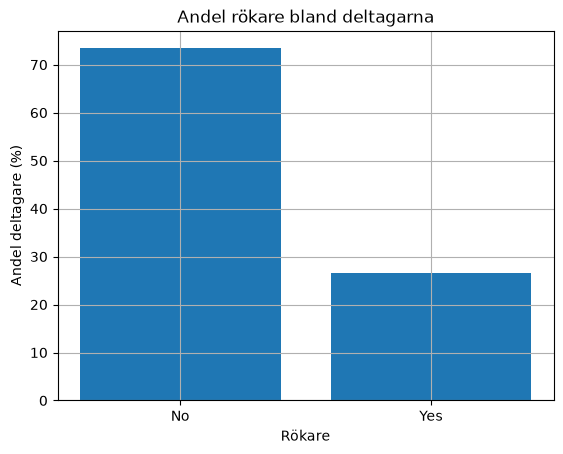

In [ ]:
antal_rokare = df["smoker"].value_counts()      #Räkna antal deltagare per kategori i smoker
andel_rokare = antal_rokare / len(df) * 100     # Gör om andel i procent antal/totalt antal deltagare * 100, len ger anatal rader i datasetet alltså 800. (v6, uppgift 6)

print(andel_rokare.round(1))        #Skriv ut andelarna avrundade till deimaltal

plt.bar(andel_rokare.index, andel_rokare.values) #Stapeldiagram. Index = Kategorierna (No, yes) på x axeln, Values, andelarna i procent staplarnas höjd

plt.title("Andel rökare bland deltagarna")
plt.xlabel("Rökare")
plt.ylabel("Andel deltagare (%)")   #Rubriker och underrubriker på olika axlarna

plt.grid(True) #Rutnät, lättare att läsa
plt.show()


Cirka 27 procent röker av deltagarna och 73 procent röker inte. Grupperna är olika stora (213 + 587 personer). Kommer användas i hypotesprövningen senare.

### Simulering

In [21]:
p_verklig = df["disease"].mean()    #andel sjuka 
n_sim = 1000        # antal personer att simulera

simulering = np.random.random(n_sim) < p_verklig    #True = sjuk ( v 4/6)

p_simulerad = simulering.mean()     #andel sjuka(v6)

print("Verklig andel: ", round(p_verklig, 4))       #andel i datasetet
print("Simulerad andel: ", round (p_simulerad, 4))      # andel i simulering
print("Skillnad: ", round(p_simulerad - p_verklig, 4))  #Simulerad minus verklig

Verklig andel:  0.0588
Simulerad andel:  0.065
Skillnad:  0.0063


Cirka 5,9 procent av deltagarna har sjukdomen, 47 av 800 personer.
När vi simulerar 1000 personer med samma risk blir 6,5 procent sjuka. Siffrorna är inte exakt lika eftersom simuleringen gör att resultatet varierar. 
Simuleringen stämmer bra med datan.